# Sudan electrification: complete system-cost accounting

**A working cost model for grid extension, mini-grids and standalone supply.**

This notebook assembles equipment, installed networks, connections, delivery, installation, project development, tax allowances, annual operation, replacements, disposal and finance. It is the cost layer for the post-war electrification study, separate from the existing 2022 dispatch model.

**Read the results as provisional budgets for fixed example designs.** We have dated Sudan equipment/fuel evidence, but no complete, comparable supplier quotations. Every numeric USD modelling input is an editable analyst assumption. Historical regional benchmarks are retained separately. No observed Sudan price is silently converted to USD, and no damage is inferred from a conflict-risk category.

| Available and checked | Still needed |
|---|---|
| Four costed examples; three cost/finance cases; annual cash flows; source register; arithmetic tests | Actual settlement design, route survey, quotations, dated FX and finance offers |
| Same annual demand target: 100 homes × 1 kWh/day = 36,500 kWh/year | Hourly/seasonal adequacy, comparable peak power, outage service and productive loads |
| Transparent upfront and 20-year costs | A validated least-cost technology recommendation or national budget |

The examples are **not optimized**. Their peak capabilities and reliability have not been matched. Lower cost here cannot establish a preferred technology.

**Reading order:** 1 Results → 2 Cost breakdown → 3 Cash flows and finance → 4 Sensitivities → 5 Evidence and assumptions → 6 Validation and next use.

[Project map](https://github.com/Elgenied/pypsa-sudan) · [Editable inputs and accounting rules](../../data/system_costs/README.md) · [Study plan](https://github.com/Elgenied/pypsa-sudan/blob/main/docs/STUDY_PLAN.md)

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from this notebook directory or the repository root, including the Desktop copy.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p/'data/system_costs/components.csv').exists())
MODEL = ROOT/'research/system_costs'
sys.path.insert(0, str(MODEL))
from cost_model import evaluate, export_results, read_csv, write_csv, RESULTS, DATA, sensitivity_rows
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
pd.set_option('display.max_colwidth', 100)
outputs = export_results()
summary = pd.DataFrame([o['summary'] for o in outputs])
central = summary.query("scenario == 'central'").set_index('case')
labels = {'standalone': 'Standalone\n100 homes', 'mini_grid': 'Mini-grid\n100 homes',
          'grid_extension': 'Grid extension\n5 km new MV', 'grid_repair_extension': 'Grid + repair\nsynthetic case'}
colors = {'standalone':'#DFAD35','mini_grid':'#269C94','grid_extension':'#446A98','grid_repair_extension':'#8C6AA6'}
def money_table(frame):
    return frame.style.format(precision=0, thousands=',').set_properties(**{'text-align':'right'})

## 1. Results: provisional budgets, not supplier quotations

The accounting horizon is **20 years**, with **10% real discounting** in the central case. Costs are held constant in real terms. “2025 USD” is an **assigned scenario price basis**, not a verified inflation conversion of the older benchmarks. The original evidence keeps its own currency and date.

These four designs all target 1 kWh/home/day, but were selected to demonstrate accounting, not to minimize cost. The grid example assumes a usable upstream source with spare capacity. The repair example adds 2 km of existing MV repair at 50% of a new line's rate and a separate upstream repair allowance. Neither describes surveyed damage.

Annual operating cost excludes replacement purchases, which appear in the cash flows and lifecycle total. All figures below include the assumed nonrecoverable import-tax allowance. An alternative total excluding that allowance is exported separately; it is not a comprehensive social cost-benefit calculation.

,Upfront USD,Upfront USD/home,Annual operations USD,20-year discounted cost USD
Standalone / 100 homes,"309,275","3,093","3,155","467,856"
Mini-grid / 100 homes,"252,440","2,524","7,068","399,890"
Grid extension / 5 km new MV,"186,516","1,865","11,898","293,462"
Grid + repair / synthetic case,"234,036","2,340","12,698","347,911"


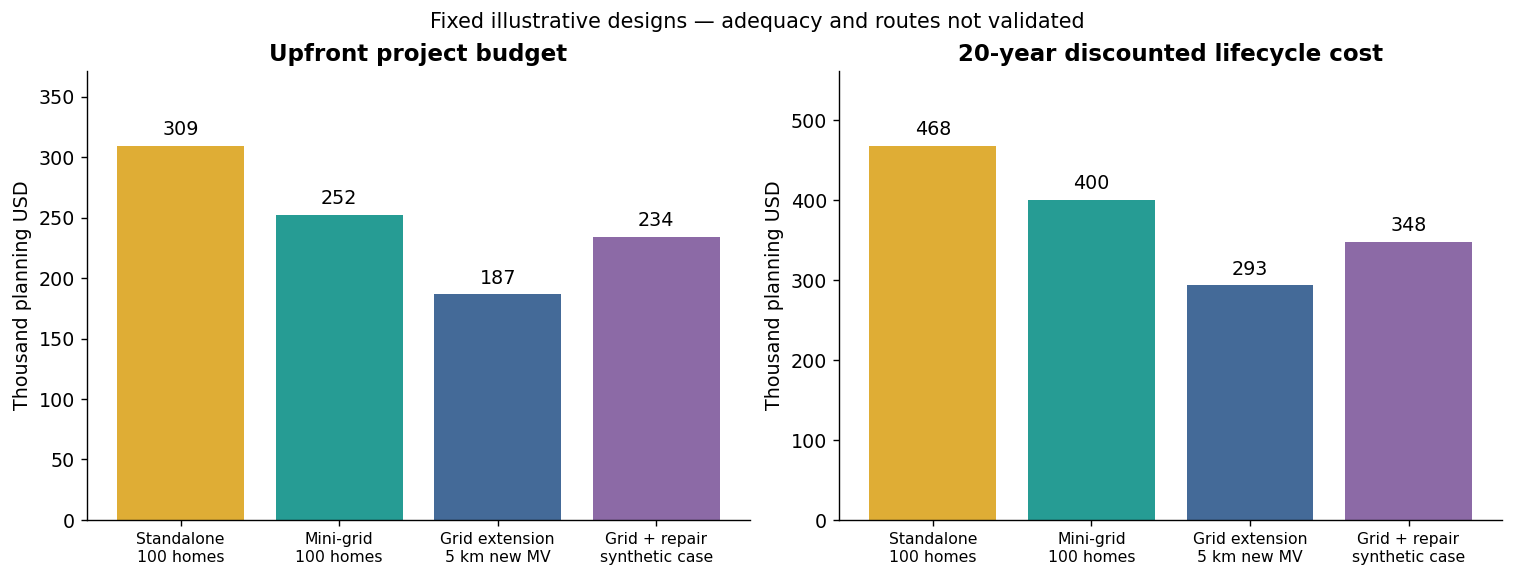

In [2]:
view = central[['initial_budget_USD','initial_USD_per_connection','annual_operating_USD','lifecycle_NPC_USD']].copy()
view.columns=['Upfront USD','Upfront USD/home','Annual operations USD','20-year discounted cost USD']
view.index=[labels[x].replace('\n',' / ') for x in view.index]
display(money_table(view))

fig, axes = plt.subplots(1,2,figsize=(12,4.5), layout='constrained')
for ax, field, title in zip(axes, ['initial_budget_USD','lifecycle_NPC_USD'],
                           ['Upfront project budget','20-year discounted lifecycle cost']):
    vals=central[field]/1000
    bars=ax.bar([labels[x] for x in vals.index], vals, color=[colors[x] for x in vals.index])
    ax.bar_label(bars,fmt='%.0f',padding=4)
    ax.set_ylabel('Thousand planning USD'); ax.set_title(title); ax.set_ylim(0,vals.max()*1.2)
    ax.tick_params(axis='x', labelsize=9)
fig.suptitle('Fixed illustrative designs — adequacy and routes not validated',fontsize=12)
fig.savefig(RESULTS/'budget_overview.png',bbox_inches='tight'); plt.show()

### What is actually being purchased?

The standalone portfolio comprises 100 separate systems, each with 1 kWp PV, 3 kWh **nominal** battery capacity and a 1 kW hybrid inverter. The mini-grid has 50 kWp PV, 150 kWh nominal batteries, a 40 kW battery inverter, a 30 kW diesel generator and 2 km of LV distribution. Battery usable energy, temperature derating and cycling need specification; nominal kWh is not delivered kWh.

Both grid examples include 5 km of new MV, one installed 100 kVA MV/LV transformer, 2 km LV, service drops/meters and basic internal wiring. All four include safe home wiring. Household appliances and productive-use equipment are outside the supply boundary.

In [3]:
boq=pd.read_csv(DATA/'bill_of_quantities.csv')
components=pd.read_csv(DATA/'components.csv')
design_table=boq.merge(components[['component','quantity_unit']],on='component',validate='many_to_one')
display(design_table.pivot(index=['component','quantity_unit'],columns='case',values='quantity').fillna(0).style.format(precision=1))
display(Markdown('Zero in this design table means **not selected**, not a missing price. MV repair is an additional case-design input: 2 route km × 50% of the new-line rate.'))

,case,grid_extension,grid_repair_extension,mini_grid,standalone
component,quantity_unit,,,,
battery,kWh_nominal,0.0,0.0,150.0,300.0
battery_inverter,kW_AC,0.0,0.0,40.0,0.0
civil_site,site,0.0,0.0,1.0,0.0
diesel_genset,kW_electric,0.0,0.0,30.0,0.0
fuel_tank_ats,system,0.0,0.0,1.0,0.0
grid_protection,site,1.0,1.0,0.0,0.0
house_wiring,connection,100.0,100.0,100.0,100.0
land_right,site_20year,0.0,0.0,1.0,0.0
lv_line,route_km,2.0,2.0,2.0,0.0


Zero in this design table means **not selected**, not a missing price. MV repair is an additional case-design input: 2 route km × 50% of the new-line rate.

## 2. What the full mini-grid budget contains

Hardware and installed work are separated. Freight and installation percentages apply only to eligible hardware; an already installed LV line is not charged installation again. The PV inverter and battery inverter have separate roles. A standalone hybrid inverter already includes MPPT, so the model rejects adding another PV inverter to that design.

The source's shipment-cost percentages divide a shipment cost basket; they are **not** percentages to apply to equipment value. Similarly, a published “distribution plus meters per customer” benchmark is only a cross-check, not an extra charge on top of explicit lines and meters.

,Component,Quantity,Unit,Unit price USD,Subtotal USD,Life years
0,pv_module,50.0,kWp,300,"15,000",25
1,pv_inverter,50.0,kW_AC,150,"7,500",10
2,battery,150.0,kWh_nominal,350,"52,500",8
3,battery_inverter,40.0,kW_AC,420,"16,800",10
4,pv_bos,50.0,kWp,120,"6,000",25
5,diesel_genset,30.0,kW_electric,650,"19,500",10
6,fuel_tank_ats,1.0,system,"1,200","1,200",15
7,lv_line,2.0,route_km,"10,000","20,000",30
8,service_meter,100.0,connection,120,"12,000",10
9,house_wiring,100.0,connection,100,"10,000",20


,Initial budget USD
component_purchase,"168,000"
international_freight,"9,480"
inland_logistics,"11,850"
installation_labour,"17,775"
engineering_development,"16,568"
contingency,"22,367"
assumed_tax,"6,399"


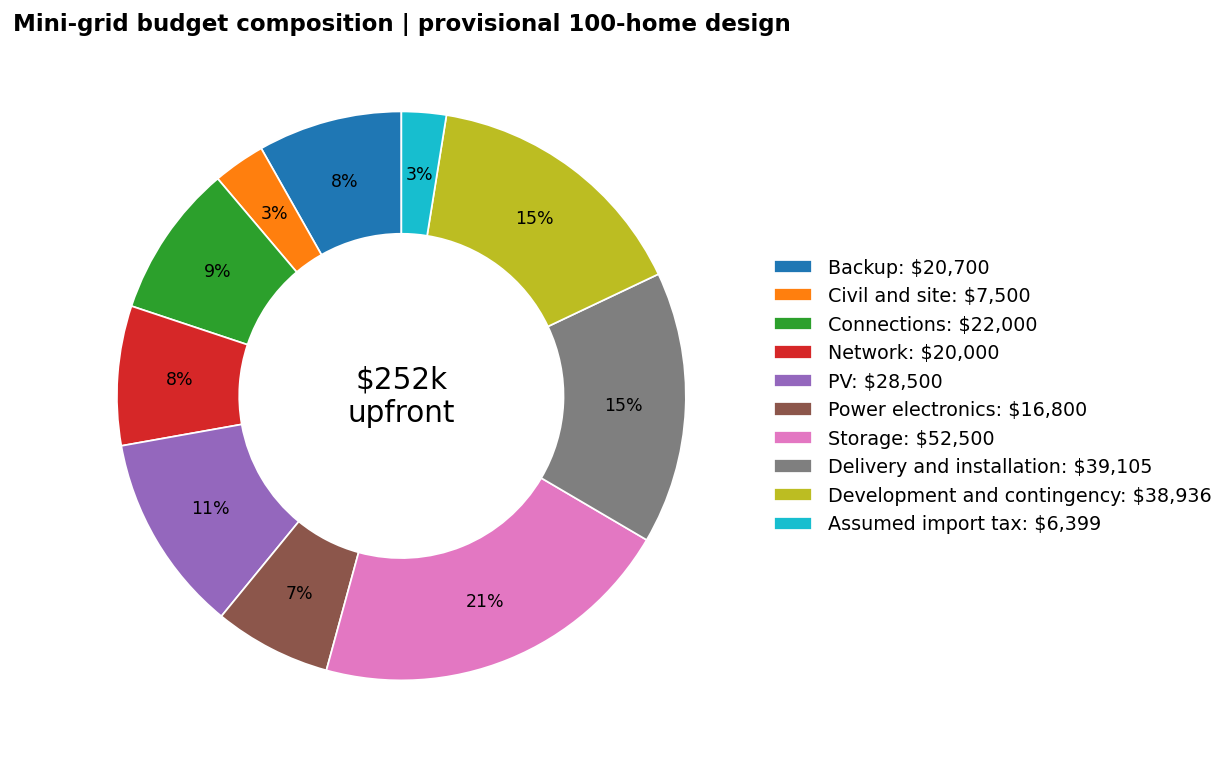

,Annual operating USD
technical_maintenance,"2,004"
insurance_allowance,840
administration,"1,200"
security_allowance,"1,000"
diesel_fuel,"1,904"
diesel_runtime_maintenance,119
grid_supply,0


In [4]:
mg=evaluate('mini_grid')
item_table=pd.DataFrame(mg['items'])[['component','quantity','quantity_unit','unit_cost','cost','life']]
item_table.columns=['Component','Quantity','Unit','Unit price USD','Subtotal USD','Life years']
display(item_table.style.format({'Quantity':'{:,.1f}','Unit price USD':'{:,.0f}','Subtotal USD':'{:,.0f}','Life years':'{:,.0f}'}))
display(money_table(pd.DataFrame.from_dict(mg['initial'],orient='index',columns=['Initial budget USD'])))

groups=pd.DataFrame(mg['items']).groupby('group')['cost'].sum()
groups['Delivery and installation']=sum(mg['initial'][x] for x in ['international_freight','inland_logistics','installation_labour'])
groups['Development and contingency']=mg['initial']['engineering_development']+mg['initial']['contingency']
groups['Assumed import tax']=mg['initial']['assumed_tax']
assert np.isclose(groups.sum(), mg['summary']['initial_budget_USD'])
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
wedges,_,_=ax.pie(groups,autopct='%1.0f%%',startangle=90,pctdistance=.78,
                  wedgeprops={'width':.43,'edgecolor':'white'},textprops={'fontsize':10})
ax.text(0,0,f"${groups.sum()/1000:,.0f}k\nupfront",ha='center',va='center',fontsize=17)
ax.legend(wedges,[f'{k}: ${v:,.0f}' for k,v in groups.items()],loc='center left',bbox_to_anchor=(1,.5),frameon=False)
ax.set_title('Mini-grid budget composition | provisional 100-home design')
fig.savefig(RESULTS/'mini_grid_cost_breakdown.png',bbox_inches='tight');plt.show()
display(money_table(pd.DataFrame.from_dict(mg['operating'],orient='index',columns=['Annual operating USD'])))

## 3. Replacements, lifecycle cost and financing

The cash-flow ledger records initial investment at year 0 and operations at each year-end. Components are replaced at their assumed life **only before** the end of the study: central-case batteries at years 8 and 16; inverters and the diesel genset at year 10. Replacement prices include applicable delivery, installation, contingency and tax, but initial development is not charged again. Removal/recycling allowances are charged when equipment retires. Prices do not decline automatically.

Baseline residual value is zero. The API can test a straight-line remaining-value credit; that accounting convention is not a resale guarantee. Construction is treated as occurring at commissioning: multi-year construction, interest during construction and working-capital timing require a later dated funding schedule.

$$NPC=C_0+sum_{t=1}^{T}rac{O_t+R_t+D_t-S_t}{(1+r)^t},qquad EAC=NPCrac{r}{1-(1+r)^{-T}}$$

$O$ is operation, $R$ replacements, $D$ disposal and $S$ residual credit. At zero discount, $EAC=NPC/T$.

The displayed cost per target kWh is $NPC/sum_t E_{target,t}/(1+r)^t$. **It becomes an LCOE only if that delivery is feasible and the operating cost assumptions are consistent with dispatch.** Here demand is constant, hence it also equals EAC/annual target energy. It is not a measured tariff or customer bill.

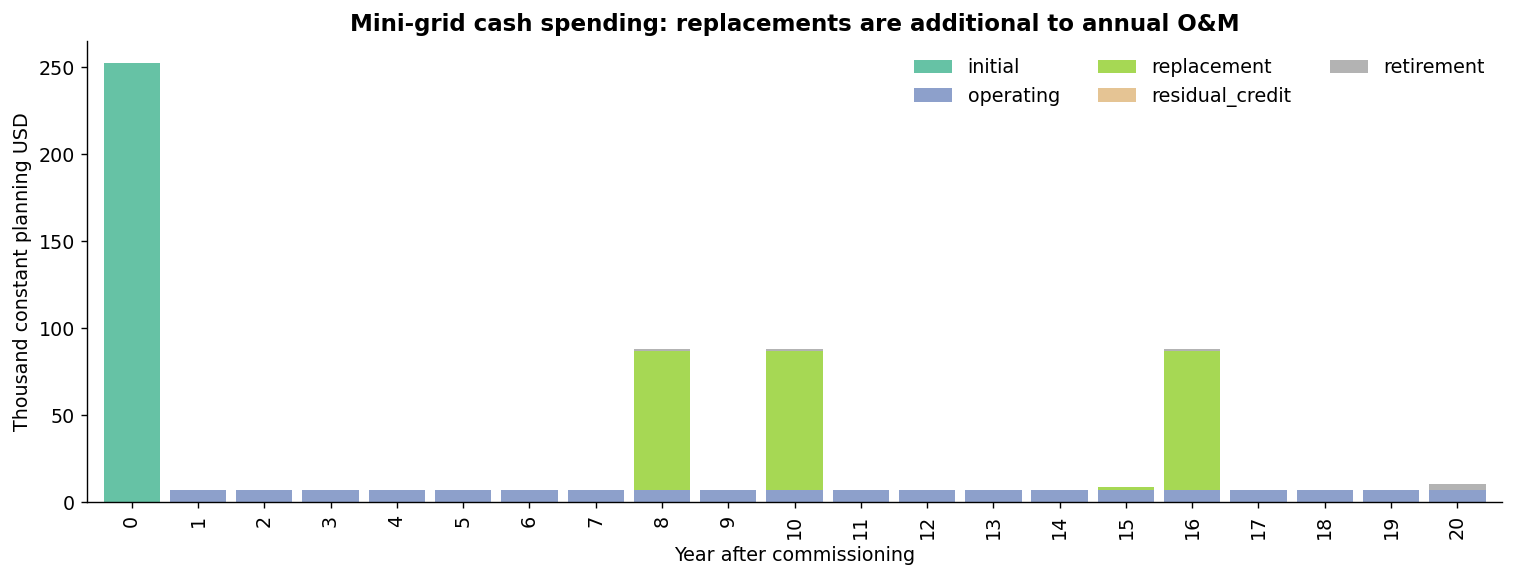

kind,initial,operating,replacement,residual_credit,retirement
year,,,,,
0,"252,440",0,0,0,0
1,0,"7,068",0,0,0
8,0,"7,068","79,642",0,"1,050"
10,0,"7,068","79,645",0,"1,116"
16,0,"7,068","79,642",0,"1,050"
20,0,"7,068",0,0,"3,330"


**Financing illustration:** 70% debt, 30% equity, no grant; 10-year loan at 10% real interest. These are scenarios, not available financing terms.

,debt_USD,equity_USD,annual_debt_service_USD,year1_operating_plus_debt_USD
Standalone / 100 homes,"216,493","92,783","35,233","38,388"
Mini-grid / 100 homes,"176,708","75,732","28,758","35,826"
Grid extension / 5 km new MV,"130,561","55,955","21,248","33,147"
Grid + repair / synthetic case,"163,825","70,211","26,662","39,360"


Debt service is shown for liquidity planning and is **not added to NPC**, which already charges the initial investment and discounts future costs. Year-1 operations plus debt service excludes equity return, replacement reserves and later replacement purchases. Grants reduce sponsor funding, not total system resource requirements.

In [5]:
ledger=pd.DataFrame(mg['ledger'])
annual=ledger.pivot_table(index='year',columns='kind',values='cost_USD',aggfunc='sum',fill_value=0)
fig,ax=plt.subplots(figsize=(12,4.5),layout='constrained')
(annual/1000).plot.bar(stacked=True,ax=ax,width=.85,colormap='Set2')
ax.set_ylabel('Thousand constant planning USD');ax.set_xlabel('Year after commissioning')
ax.set_title('Mini-grid cash spending: replacements are additional to annual O&M')
ax.legend(title='',ncol=3,frameon=False)
fig.savefig(RESULTS/'lifetime_cashflows.png',bbox_inches='tight');plt.show()
display(money_table(annual.loc[[0,1,8,10,16,20]]))

fin=central[['debt_USD','equity_USD','annual_debt_service_USD','year1_operating_plus_debt_USD']].copy()
fin.index=[labels[x].replace('\n',' / ') for x in fin.index]
display(Markdown('**Financing illustration:** 70% debt, 30% equity, no grant; 10-year loan at 10% real interest. These are scenarios, not available financing terms.'))
display(money_table(fin))
display(Markdown('Debt service is shown for liquidity planning and is **not added to NPC**, which already charges the initial investment and discounts future costs. Year-1 operations plus debt service excludes equity return, replacement reserves and later replacement purchases. Grants reduce sponsor funding, not total system resource requirements.'))

## 4. Which assumptions matter?

The combined lower-input and higher-input cases are stress scenarios, **not confidence intervals**. They change equipment costs, delivery allowances, battery life and financing together. For interpretation, the second chart varies one input at a time from the central case.

Grid distance is route length, not the atlas's straight-line distance to a possibly unsuitable line. No crossing of these curves is reported as an economically validated connection threshold: generation adequacy, grid service and routing have not yet been checked.

scenario,lower_input,central,higher_input
Standalone / 100 homes,0.55,1.51,5.50
Mini-grid / 100 homes,0.50,1.29,4.39
Grid extension / 5 km new MV,0.39,0.94,2.75
Grid + repair / synthetic case,0.46,1.12,3.41


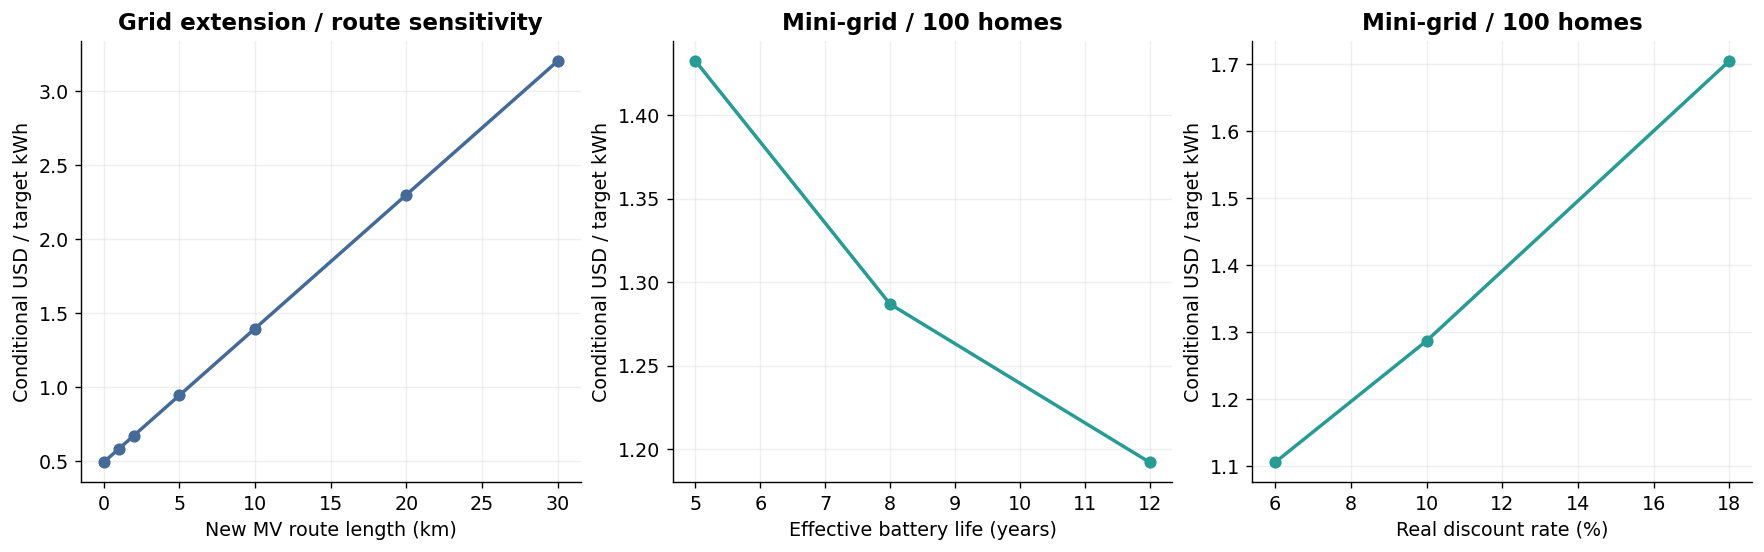

In [6]:
comparison=summary.pivot(index='case',columns='scenario',values='conditional_USD_per_target_kWh').reindex(central.index)
comparison=comparison[['lower_input','central','higher_input']]
comparison.index=[labels[x].replace('\n',' / ') for x in comparison.index]
display(comparison.style.format('{:.2f}').set_caption('Conditional USD per target kWh — no feasibility-certified winner'))

sens=pd.read_csv(RESULTS/'sensitivity.csv')
fig,axes=plt.subplots(1,3,figsize=(14,4.3),layout='constrained')
specs=[('grid_extension','new_MV_route_km','New MV route length (km)'),
       ('mini_grid','battery_life_years','Effective battery life (years)'),
       ('mini_grid','real_discount_rate','Real discount rate (%)')]
for ax,(case,driver,xlabel) in zip(axes,specs):
    s=sens.query('case == @case and driver == @driver').sort_values('value')
    x=s.value*100 if driver=='real_discount_rate' else s.value
    ax.plot(x,s.conditional_USD_per_target_kWh,marker='o',color=colors[case],linewidth=2)
    ax.set_xlabel(xlabel);ax.set_ylabel('Conditional USD / target kWh')
    ax.set_title('Grid extension / route sensitivity' if driver=='new_MV_route_km' else labels[case].replace('\n',' / '));ax.grid(alpha=.2)
fig.savefig(RESULTS/'sensitivities.png',bbox_inches='tight');plt.show()

## 5. Evidence versus modelling assumptions

**What the Sudan reports actually give us:** dated battery and inverter/panel prices in SDG, indicative local diesel prices, and evidence about delivery/payment constraints. They do not supply a complete compatible system, installation scope, FX rate, verified battery lifespan or current route costs.

The battery table below retains city and date. A 200 Ah battery without voltage cannot be converted into kWh. The panel table's printed “590 kW” is unresolved, so it is not normalized into a panel cost per kW. The separate 550 W interview quote is not used to silently correct that table. Do not combine quotes across dates/specifications into a supposedly contemporaneous turnkey offer.

In [7]:
evidence=ROOT/'data/report_evidence'
if evidence.exists():
    prices=pd.read_csv(evidence/'market_prices_2025.csv')
    batteries=prices.query("product == 'lithium_ion_battery'")
    display(batteries[['data_period','city','price_SDG','nominal_energy_kWh','derived_SDG_per_nominal_kWh']]
            .style.format({'price_SDG':'{:,.0f}','nominal_energy_kWh':'{:,.0f}','derived_SDG_per_nominal_kWh':'{:,.0f}'},na_rep='No quote'))
    fuel=pd.read_csv(evidence/'fuel_prices_2024.csv')
    display(fuel.query("fuel == 'diesel'")[['data_period','location','price_SDG_per_litre','availability']]
            .style.format({'price_SDG_per_litre':'{:,.0f}'},na_rep='No quote'))
else:
    display(Markdown('Local report evidence was not copied here. See the repository data/report_evidence collection.'))

,data_period,city,price_SDG,nominal_energy_kWh,derived_SDG_per_nominal_kWh
12,2025-09-18,Atbara,"5,400,000",10,"540,000"
13,2025-09-18,Port Sudan,"5,094,000",10,"509,400"
14,2025-09-18,Dongola,No quote,10,No quote
15,2025-09-18,Khartoum,"5,094,000",10,"509,400"
16,2025-09-28,Atbara,"5,300,000",10,"530,000"
17,2025-09-28,Port Sudan,"5,227,000",10,"522,700"
18,2025-09-28,Dongola,No quote,10,No quote
19,2025-09-28,Khartoum,"5,227,000",10,"522,700"
20,2025-10-16,Atbara,"5,000,000",10,"500,000"
21,2025-10-16,Port Sudan,"5,300,000",10,"530,000"


,data_period,location,price_SDG_per_litre,availability
0,2024-08,Port Sudan,"2,711",available; no black market reported
2,2024-08,Shandi,"2,800",no black market reported
4,2024-08,Sinnar,No quote,unavailable in stations and black market
6,2024-08,Kosty,"8,333",black market only; stations out of service
8,2024-08,Omdurman,"3,050",gasoline price not reported
10,2024-08,Darfur region; Khartoum city; Kordofan region,No quote,black market dependence; no prices given


### The editable cost assumptions

All USD values in the next table are **provisional analyst inputs** on the assigned constant-2025 basis. They are neither inferred FX conversions nor automatically inflated historical costs. The anchor column in `components.csv` points to benchmark evidence or explains that a value is an unsourced allowance. Quantity and scope matter as much as unit price.

The ESMAP handbook provides useful historical multi-country component benchmarks; the separate regional grid inputs come from a **South Sudan** study, not Sudan. We use them as context and retain their dates/definitions. The detailed source URLs, page numbers and downloaded-file hashes are in `sources.json` and `benchmark_evidence.csv`.

In [8]:
display(components[['component','quantity_unit','low_USD','base_USD','high_USD','life_years','annual_om_fraction']]
        .style.format({'low_USD':'{:,.0f}','base_USD':'{:,.0f}','high_USD':'{:,.0f}',
                       'life_years':'{:,.0f}','annual_om_fraction':'{:.1%}'}))
params=pd.read_csv(DATA/'scenario_parameters.csv')
display(params[['parameter','lower_input','central','higher_input','unit']].style.format(precision=3))
display(Markdown('Component lifetimes are fixed except battery life, which is overridden by the scenario parameter. Rates use fractions: 0.10 means 10%. A blank source price is never interpreted as zero.'))

,component,quantity_unit,low_USD,base_USD,high_USD,life_years,annual_om_fraction
0,pv_module,kWp,200,300,500,25,1.0%
1,pv_inverter,kW_AC,80,150,250,10,1.0%
2,battery,kWh_nominal,250,350,550,8,0.5%
3,battery_inverter,kW_AC,300,420,700,10,1.0%
4,shs_hybrid_inverter,kW_AC,200,350,600,10,1.0%
5,pv_bos,kWp,60,120,220,25,1.0%
6,diesel_genset,kW_electric,450,650,"1,000",10,3.0%
7,fuel_tank_ats,system,500,"1,200","2,500",15,2.0%
8,mv_line,route_km,"12,000","20,000","35,000",30,2.0%
9,lv_line,route_km,"5,000","10,000","18,000",30,2.0%


,parameter,lower_input,central,higher_input,unit
0,horizon_years,20.000,20.000,20.000,year
1,real_discount_rate,0.060,0.100,0.180,fraction
2,international_freight,0.040,0.080,0.150,fraction_imported_hardware
3,nonrecoverable_tax,0.000,0.050,0.150,fraction_imported_plus_international_freight
4,inland_logistics,0.030,0.100,0.250,fraction_transport_eligible_hardware
5,equipment_installation,0.080,0.150,0.250,fraction_labour_eligible_hardware
6,engineering_development,0.040,0.080,0.120,fraction_direct_resource_cost
7,contingency,0.050,0.100,0.200,fraction_direct_plus_engineering
8,battery_life_years,12.000,8.000,5.000,year
9,insurance_fraction,0.000,0.005,0.020,fraction_component_purchase_cost_per_year


Component lifetimes are fixed except battery life, which is overridden by the scenario parameter. Rates use fractions: 0.10 means 10%. A blank source price is never interpreted as zero.

## 6. What was checked, what remains missing, and how to use this

The checks below exercise accounting against hand-calculated cases: a zero-interest annuity, loan repayment, a replacement at year 5 but not at retirement, discounted residual value, losses/fuel units, installed-price scope, grant/debt separation and input errors. These validate the implementation's arithmetic, **not the real-world prices or the service feasibility**.

In [9]:
check=subprocess.run([sys.executable,str(MODEL/'check_costs.py')],capture_output=True,text=True)
if check.returncode:
    raise RuntimeError(check.stdout+'\n'+check.stderr)
validation=json.loads((RESULTS/'validation.json').read_text())
display(pd.DataFrame([validation]))
coverage=pd.read_csv(DATA/'coverage.csv')
display(coverage[['cost_or_requirement','status','needed_to_upgrade']])

,checks_run,failures,errors,passed,scope
0,9,0,0,True,"Accounting, dimensions and limiting cases; not independent validation of costs or feasibility"


,cost_or_requirement,status,needed_to_upgrade
0,"PV, storage and conversion",included_provisional,"Supplier quotations, DoD, efficiency, heat derating, warranties"
1,"Freight, port and inland delivery",included_provisional,"Actual shipment value, route, cargo scope and cost; source shipment shares cannot be applied as ..."
2,Installation and commissioning,included_provisional,BOM/EPC offer and contractor scope
3,"MV/LV, transformer and connection",included_provisional,"Route, conductor, poles, voltage drop, protection and quotes"
4,"Engineering, permits and contingency",included_provisional,Actual project development and fiscal treatment
5,"Fuel, energy, O&M and administration",included_provisional,"Hourly dispatch, delivered fuel, upstream supply cost and service contract"
6,Replacements and disposal,included_provisional,"Cycle/temperature life, actual spares and recycling offers"
7,Finance and collections,included_provisional,"Finance offer, subsidy design, affordability and collection evidence"
8,Conflict damage and repair,synthetic_case_only,Asset condition survey and repair BOM/time; never infer from DRE risk class
9,Grid reliability and upstream expansion,unvalidated_boundary,"Available MW, hourly outages, source rehabilitation and backup adequacy"


### Change one assumption and recalculate

Edit `data/system_costs/components.csv` for prices, equipment life and O&M; `scenario_parameters.csv` for logistics, finance, fuel and effective battery life; `bill_of_quantities.csv` for equipment/route quantities; and `case_designs.csv` for demand, losses and repair assumptions. **Run All** to regenerate every result. Do not edit result CSVs as inputs. Changing quantities does not trigger a capacity optimizer or certify adequacy.

The following example changes mini-grid battery life without changing the source evidence. It does not alter the saved central scenario.

In [10]:
example=evaluate('mini_grid',overrides={'battery_life_years':5})['summary']
display(pd.DataFrame([{'case':'Central: 8-year battery',
                       'NPC_USD':mg['summary']['lifecycle_NPC_USD']},
                      {'case':'Sensitivity: 5-year battery','NPC_USD':example['lifecycle_NPC_USD']}]))

,case,NPC_USD
0,Central: 8-year battery,399890.409081
1,Sensitivity: 5-year battery,445217.011951


### Use in PyPSA and the next study step

1. Select a small, geographically varied settlement sample. Establish household counts, critical/productive loads and the same hourly service requirement for each option. DRE buildings are not automatically customer accounts.
2. Obtain comparable quotations and route surveys. Replace the highest-impact provisional inputs first: installed MV/LV, usable battery life and price, delivery, repair BOM, bulk supply and delivered fuel. Record quote date, currency, FX convention, specification and what is included.
3. Optimize generation/storage and dispatch chronologically for each candidate service arrangement. Keep battery **energy** and inverter **power** separate. Confirm unmet load, peaks and seasonal performance before computing an LCOE or comparing options.
4. Apply the full cost ledger to feasible designs, then compare under finance, demand, fuel-access and damage scenarios. Shared feeders must be costed once when scaling beyond individual sites.

For a one-year PyPSA objective, `capital_cost` must be periodized, not raw USD/kW CAPEX. Convert USD/kW-year to USD/MW-year (×1,000); storage energy USD/kWh-year to USD/MWh-year (×1,000). A `Store` with charging/discharging `Link`s permits independent power/energy sizing. Link power is defined at its input, so efficiency and rating conventions must be reconciled. Charge the physical bidirectional converter once, not independently on both links. Fixed route/connection costs need activation/choice logic rather than an arbitrary per-MW capacity coefficient.

At the central fuel assumptions, diesel's simple variable electric-output cost is `(1.5 USD/litre × 0.32 litre/kWh + 0.03 USD/kWh) × 1,000 = 510 USD/MWh`. This already uses electrical-output fuel consumption; do not divide by efficiency again. The per-litre input remains provisional and the annual diesel share used in this notebook must be replaced by dispatch.

**This notebook does not change the 2022 model or claim a least-cost Sudan map. It supplies the cost accounting needed to build and audit that comparison.**

### References

- [ESMAP (2022), Mini Grids for Half a Billion People](https://documents1.worldbank.org/curated/en/099635009232259510/pdf/P1751510dd4ab407e083a6098d1905fa94f.pdf), Table 1.4, physical PDF page 85 / printed page 57. Historical benchmarks; not a Sudan quote.
- [World Bank, South Sudan high-level electrification prospectus](https://documents1.worldbank.org/curated/en/099062423121020382/pdf/P175227003a74408f0bc3a075ae51a5747e.pdf), Annex Table 4, PDF pages 27–28. South Sudan planning assumptions, not Sudan observations.
- [Sudan report evidence source register](../../data/report_evidence/source_register.csv): R17, UNDP 2026 solar value-chain study, PDF pages 29 and 31; R12, World Bank August 2024 electricity snapshot, PDF pages 9–10.
- [PyPSA 1.0.6 Generator](https://docs.pypsa.org/v1.0.6/user-guide/components/generators/) and [Store](https://docs.pypsa.org/v1.0.6/user-guide/components/stores/) component documentation.